In [2]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import Plot_Background,plot_quivers,CircleCalc,ImageS

In [3]:
def readh5(H5FileName):
    h5image=h5py.File(H5FileName,'r')
    data_id = [key for key in h5image.keys()]
    tot_block = h5image[data_id[4]].shape[0]
    block_line = round(np.sqrt(tot_block))
    tot_pixel = h5image[data_id[4]].shape[1]
    pixel_line = round(np.sqrt(tot_pixel))
    resolution = block_line*pixel_line # should be ?*?
    print("resolution: ",resolution)

    image = np.zeros((resolution,resolution,4))

    for j in range(4):
        block_index = np.indices((block_line, block_line))  # 生成块的索引
        pixel_index = np.indices((pixel_line, pixel_line))  # 生成像素的索引

        # 计算每个块在高分辨率图像中的位置
        block_x = block_index[0].flatten() * pixel_line
        block_y = block_index[1].flatten() * pixel_line

        # 计算每个像素在块中的位置
        pixel_x = pixel_index[0].flatten()
        pixel_y = pixel_index[1].flatten()

        # 组合块和像素的索引
        high_res_x = block_x[:, np.newaxis] + pixel_x[np.newaxis, :]
        high_res_y = block_y[:, np.newaxis] + pixel_y[np.newaxis, :]

        # 从 h5image 中提取数据并赋值到高分辨率图像
        image[high_res_x.flatten(), high_res_y.flatten(), j] = np.array(h5image[data_id[j]]).flatten()

    h5image.close()
    return image

In [8]:
grmhdData1600=np.zeros((17,100,100,4))
for i in range(17):
    grmhdData1600[i,:,:,:] = readh5(f"data/data001600.dat/img_data_{i}.h5")
np.save("data/grmhdData1600.npy", grmhdData1600)

resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100
resolution:  100


In [7]:
def readh5ALL(rootdir="/home/yuxin/Work/Work/EHT/raptor_run/output/MAD_a+15o16/a094-high/",start=1600,end=3000,gap=10):
    grmhdData=np.zeros((100,100,4,17,(end-start)//gap))
    for t in range(start,end,gap):
        for i in range(17):
            H5FileName=f"{rootdir}/data{t}.dat/img_data_{i}.h5"
            grmhdData[:,:,:,i,t]=readh5(H5FileName)
    return grmhdData


In [3]:
# def readh5(datadir):
#     # H5FileName=os.path.join(datadir,"img_data_0.h5")
#     H5FileName=datadir
#     h5image=h5py.File(H5FileName,'r')
#     data_id = [key for key in h5image.keys()]
#     tot_block = h5image[data_id[4]].shape[0]
#     block_line = round(np.sqrt(tot_block))
#     tot_pixel = h5image[data_id[4]].shape[1]
#     pixel_line = round(np.sqrt(tot_pixel))
#     resolution = block_line*pixel_line # should be ?*?
#     print("resolution: ",resolution)

#     datalist = np.zeros((17,resolution,resolution,4))

#     for i in range(0,17):
#         H5FileName=os.path.join(datadir,f"img_data_{i}.h5")
#         h5image=h5py.File(H5FileName,'r')

#         image = np.zeros((resolution,resolution,4))

#         for j in range(4):
#             block_index = np.indices((block_line, block_line))  # 生成块的索引
#             pixel_index = np.indices((pixel_line, pixel_line))  # 生成像素的索引

#             # 计算每个块在高分辨率图像中的位置
#             block_y = block_index[0].flatten() * pixel_line
#             block_x = block_index[1].flatten() * pixel_line

#             # 计算每个像素在块中的位置
#             pixel_y = pixel_index[0].flatten()
#             pixel_x = pixel_index[1].flatten()

#             # 组合块和像素的索引
#             high_res_y = block_y[:, np.newaxis] + pixel_y[np.newaxis, :]
#             high_res_x = block_x[:, np.newaxis] + pixel_x[np.newaxis, :]

#             # 从 h5image 中提取数据并赋值到高分辨率图像
#             image[high_res_x.flatten(), high_res_y.flatten(), j] = np.array(h5image[data_id[j]]).flatten()
        
#         datalist[i] = image
#         h5image.close()
#     return datalist

In [8]:

datalist=readh5("img_data_0_high_res.h5")
datalistafterImageS=np.zeros(datalist.shape)
tmp=ImageS(datalist,blur=False)
datalistafterImageS[:,:,0]=tmp.I
datalistafterImageS[:,:,1]=tmp.Q
datalistafterImageS[:,:,2]=tmp.U
datalistafterImageS[:,:,3]=tmp.V

resolution:  400


In [9]:
image_list_high_res=np.load("image_list_high_res.npy")

In [12]:
from libanaly import Plot_Background,plot_quivers,CircleCalc,ImageS

In [34]:
xxx=np.sum(image_list_high_res,axis=0)[:,:,0]
xxx[:246,:]=0

In [37]:
(246-157)/400*2*23.1131/2

5.14266475

/tmp/ipykernel_56570/1448739214.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  figure.show()


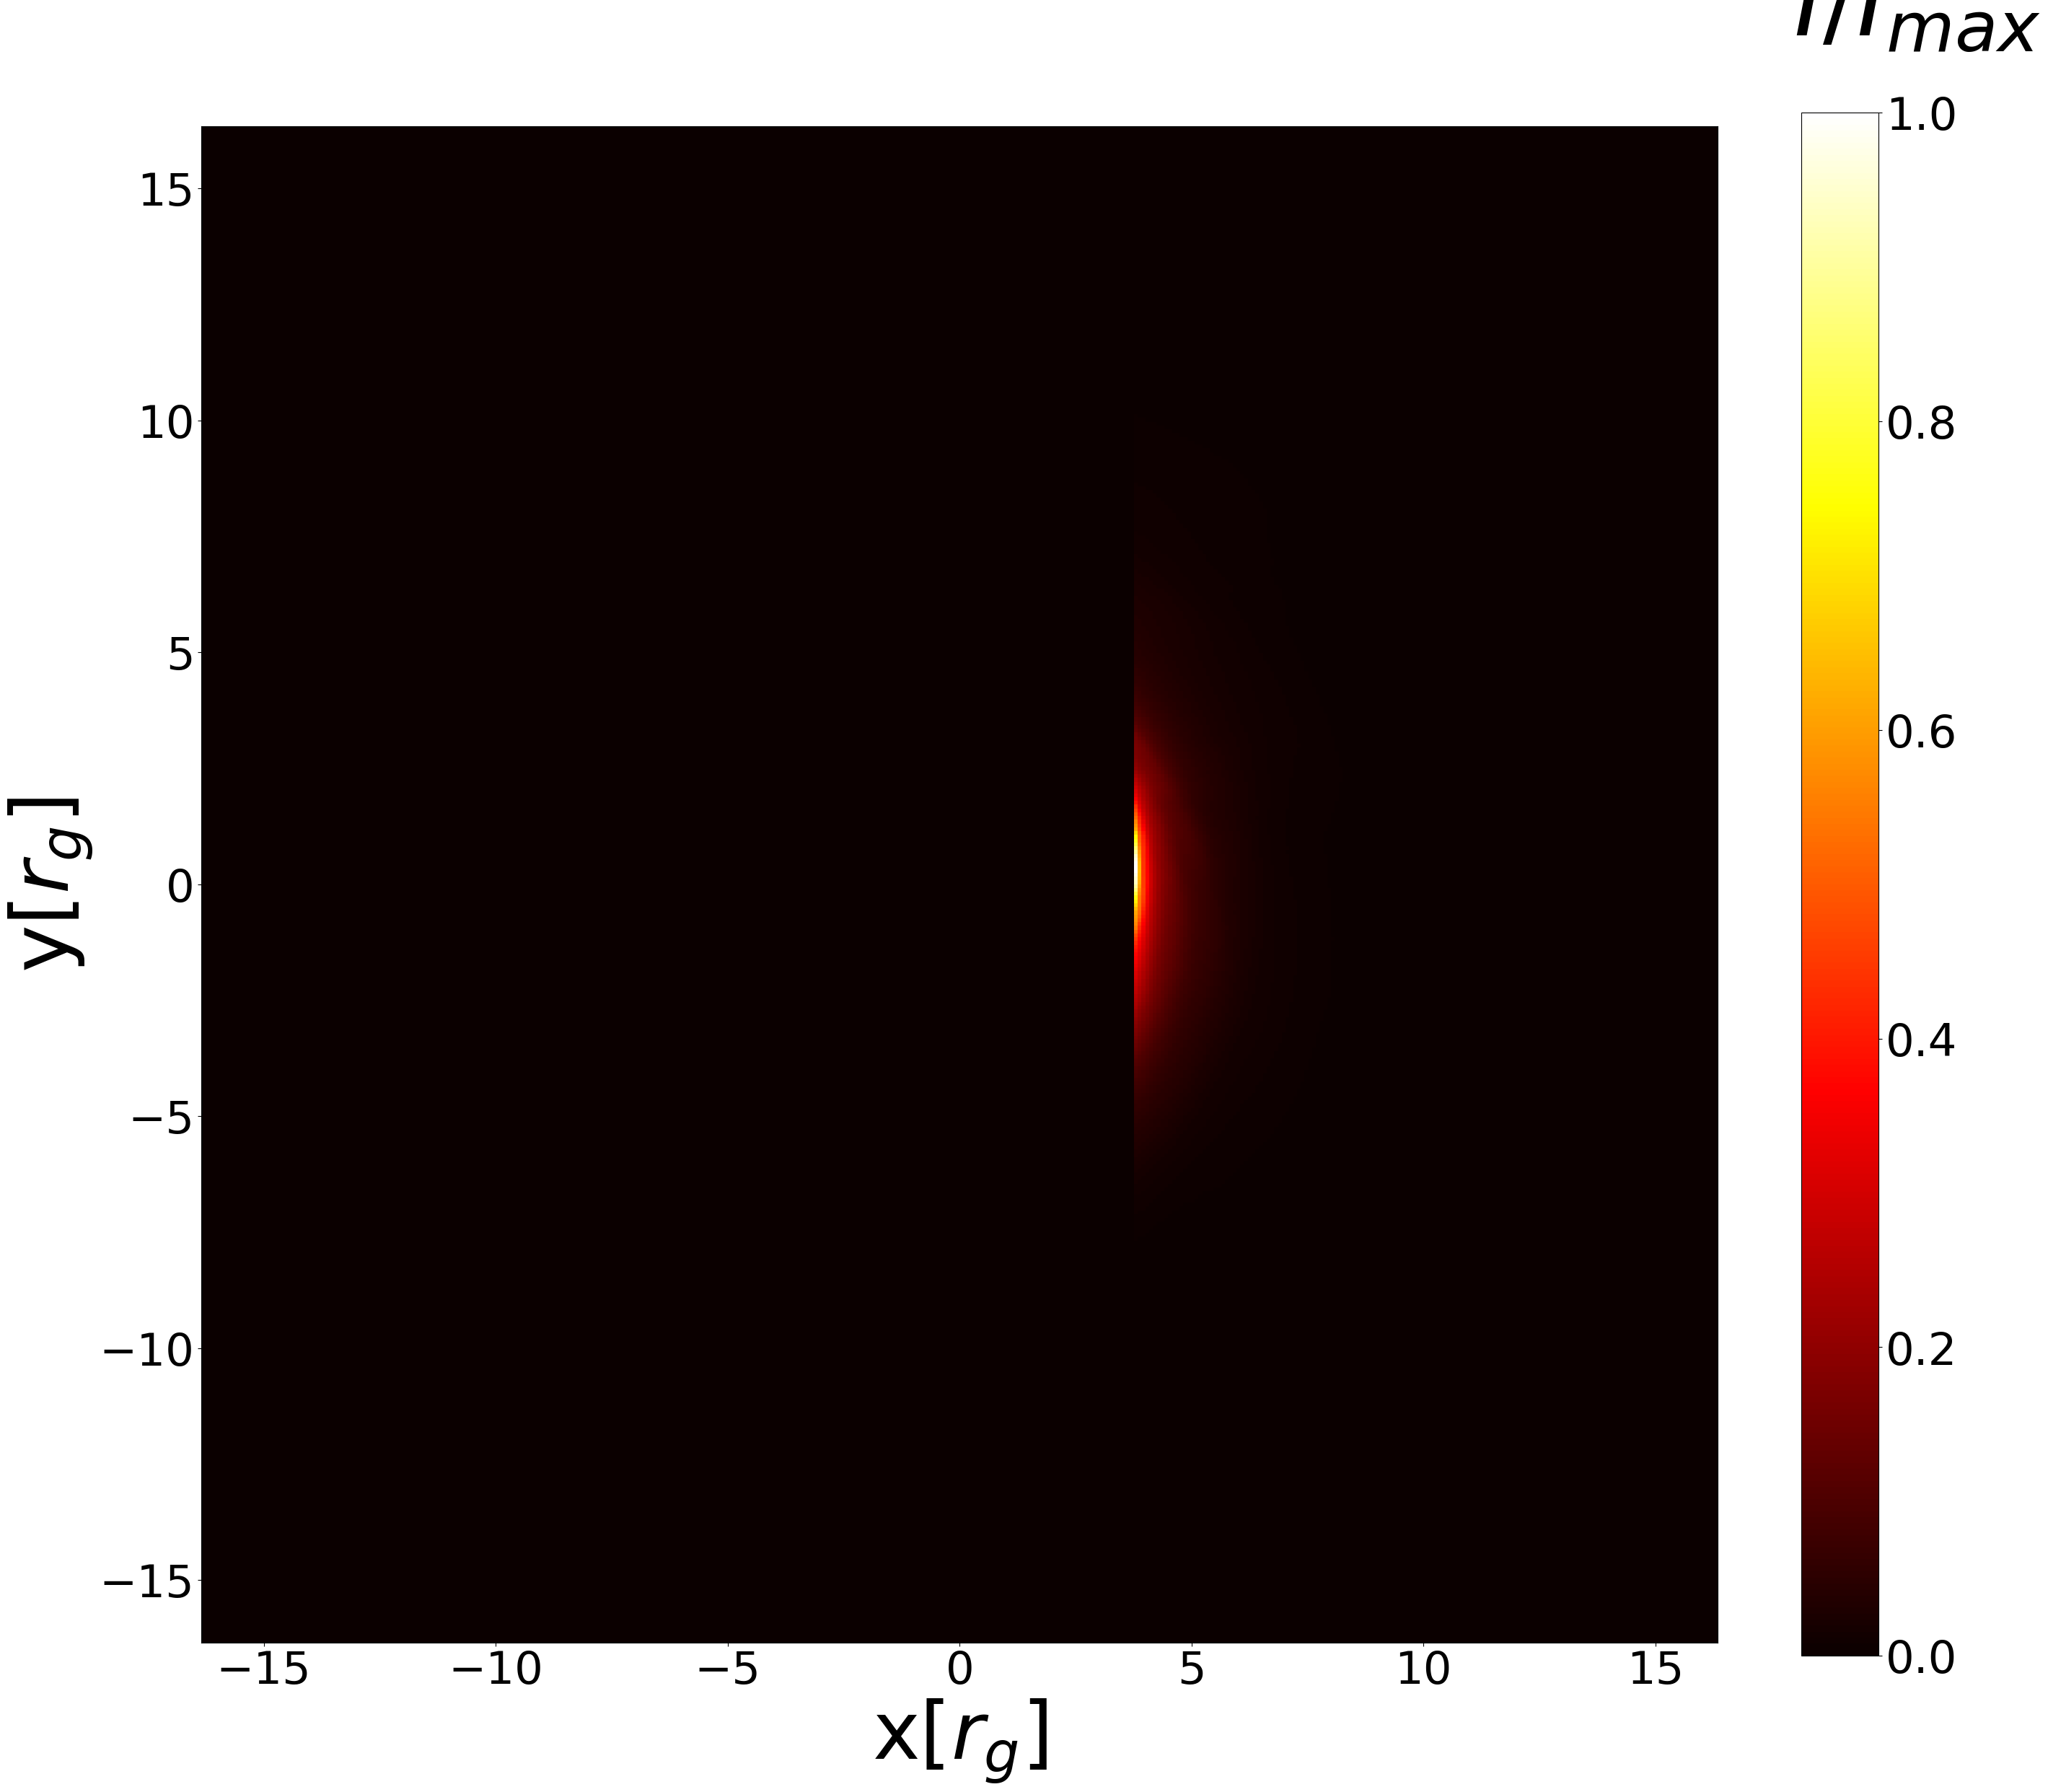

In [35]:
# plt.imshow(np.sum(image_list_high_res,axis=0)[:,:,0],cmap='afmhot')
figure,ax0 = plt.subplots(figsize=(30,30)) 
# ax0.set_xlim(-15,15)
ax0.set_xlabel('x[$r_g$]',size=80)
# ax0.set_ylim(-15,15)
ax0.set_ylabel('y[$r_g$]',size=80)
plt.tick_params(labelsize=45)
# plt.xticks([-10,-5,0,5,10])
# plt.yticks([-10,-5,0,5,10])
Plot_Background(figure,ax0,xxx)
figure.show()
figure.savefig("averageI.png")

In [14]:
P=np.sqrt(tmp.Q**2+tmp.U**2)
EVPA=tmp.evpa/180*np.pi

In [17]:
P

array([[1.08521599e+15, 1.08446995e+15, 1.03829714e+15, ...,
        6.87641963e+13, 6.39729026e+13, 5.89202661e+13],
       [1.04806728e+15, 1.00254462e+15, 9.79769320e+14, ...,
        7.29594750e+13, 6.77027854e+13, 6.13800987e+13],
       [9.84489103e+14, 9.66869460e+14, 9.72279724e+14, ...,
        7.61269395e+13, 6.99030443e+13, 6.30416159e+13],
       ...,
       [1.69574078e+15, 1.59042907e+15, 1.40572010e+15, ...,
        5.06757003e+15, 5.08983944e+15, 5.11456307e+15],
       [1.65213199e+15, 1.62133721e+15, 1.36708943e+15, ...,
        5.27694148e+15, 5.23810663e+15, 5.25431973e+15],
       [1.64461094e+15, 1.70606917e+15, 1.41729556e+15, ...,
        5.48276593e+15, 5.44667446e+15, 5.40130378e+15]])

In [8]:
EVPA.shape

(400, 400)

In [15]:
plt.imshow(EVPA,cmap='hsv')


In [16]:
fig,ax=plot_quivers(datalistafterImageS[:,:,0],P,EVPA)
fig.show()
fig.savefig("quivers.png")


/tmp/ipykernel_1891949/981057662.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
